# Milestone 3: Low-Rank Prediction
Project 2: A Movie Recommendation System — MATH 344L

In this notebook I use the SVD to fill in missing ratings and compare the results with the Milestone 2 baseline on the same hidden test ratings.

In [1]:
USER, REPO = "JayCBak", "recommendation_system"
!rm -rf {REPO}
!git clone -q https://github.com/{USER}/{REPO}.git

import sys
sys.path.insert(0, f"{REPO}/src")
from evaluate import split_ratings, to_matrix, rmse
from models import baseline

This cell downloads a fresh copy of my GitHub repository into Colab and tells Python to look in the `src` folder. Then it imports the functions I wrote in Milestone 2, so this notebook uses exactly the same split and the same RMSE as before. `baseline` is the same function as `bias_baseline` from Milestone 2 (it calculates μ, the user effects, and the movie effects).

In [2]:
import os, urllib.request, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if not os.path.exists("ml-100k"):
    urllib.request.urlretrieve(
        "https://files.grouplens.org/datasets/movielens/ml-100k.zip",
        "ml-100k.zip")
    zipfile.ZipFile("ml-100k.zip").extractall()

ratings = pd.read_csv("ml-100k/u.data", sep="\t",
                      names=["user", "item", "rating", "time"])

train, test = split_ratings(ratings)   # seed=0, as in Milestone 2
R = to_matrix(train)
known = ~np.isnan(R)

truth = test["rating"].to_numpy()
u = test["user"].to_numpy() - 1
i = test["item"].to_numpy() - 1
print("train:", len(train), " test:", len(test))

train: 90032  test: 9968


This loads the MovieLens 100K ratings and makes the same train/test split as Milestone 2. I got **90032 training and 9968 test ratings**, which matches my Milestone 2 notebook exactly, so the comparisons are fair. (The handout shows 89824 / 10176; the split depends on the library versions, so my numbers in this notebook are slightly different from the handout's, but they are consistent with my own Milestone 2.) `truth`, `u`, and `i` hold the hidden ratings and their row/column positions.

In [3]:
def score(P):
    """Test RMSE of a full 943 x 1682 prediction matrix P."""
    return rmse(np.clip(P[u, i], 1, 5), truth)

`score` takes a full prediction matrix and only looks at the entries where there is a hidden test rating (`P[u, i]`). It clips the predictions to 1–5 stars and returns the test RMSE. Every model below is scored this way.

In [4]:
def baseline_matrix(R):
    """Full matrix of baseline predictions mu + b_user + b_item."""
    mu, b_user, b_item = baseline(R)
    return mu + b_user[:, None] + b_item[None, :]

B = baseline_matrix(R)
print("shape:", B.shape)
print("baseline test RMSE:", round(score(B), 4))

shape: (943, 1682)
baseline test RMSE: 0.9545


This builds the whole baseline prediction matrix. `b_user[:, None]` is a column and `b_item[None, :]` is a row, and adding them makes NumPy fill a 943 × 1682 table where entry (u, i) is μ + b_u + b_i (broadcasting). The RMSE is **0.9545**, the same as my "user + movie effects" score in Milestone 2. This is the number to beat.

In [5]:
def rank_k(U, s, Vt, k):
    """Rank-k matrix from an SVD that was already computed."""
    return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

`rank_k` keeps only the first k singular values and vectors and multiplies them back together. By Eckart–Young this is the best rank-k approximation. Computing the SVD once and slicing it lets me try many values of k quickly.

## Model 1: fill the gaps with each movie's average

In [6]:
mu = np.nanmean(R)
n_item = known.sum(axis=0)
item_mean = np.full(R.shape[1], mu)
has_rating = n_item > 0
item_mean[has_rating] = np.nansum(R, axis=0)[has_rating] / n_item[has_rating]

F = np.where(known, R, item_mean[None, :])
U1, s1, Vt1 = np.linalg.svd(F, full_matrices=False)

The first lines compute each movie's average rating from the training data (movies with no ratings get the overall average). `np.where(known, R, item_mean[None, :])` keeps the real ratings and puts the movie average in every gap, so `F` has no `nan` and the SVD can be computed.

## Model 2: subtract the baseline first

In [7]:
X = np.where(known, R - B, 0.0)
U2, s2, Vt2 = np.linalg.svd(X, full_matrices=False)

Here the SVD only has to explain what the baseline misses. `R - B` is how much each user liked a movie compared to the baseline's guess. The gaps get 0, which means "no information beyond the baseline" (not zero stars). After the rank-k approximation I add `B` back to get back to stars.

## Test error against k

In [8]:
ks = [1, 2, 3, 5, 10, 15, 20, 30, 50, 100, 200, 400, 943]
err1, err2 = [], []
for k in ks:
    err1.append(score(rank_k(U1, s1, Vt1, k)))
    err2.append(score(rank_k(U2, s2, Vt2, k) + B))
    print(f"k = {k:3d}  model 1: {err1[-1]:.4f}  model 2: {err2[-1]:.4f}")

k =   1  model 1: 1.0060  model 2: 0.9428
k =   2  model 1: 0.9917  model 2: 0.9368
k =   3  model 1: 0.9884  model 2: 0.9356
k =   5  model 1: 0.9790  model 2: 0.9304
k =  10  model 1: 0.9726  model 2: 0.9256
k =  15  model 1: 0.9742  model 2: 0.9250
k =  20  model 1: 0.9745  model 2: 0.9261
k =  30  model 1: 0.9763  model 2: 0.9300
k =  50  model 1: 0.9876  model 2: 0.9363
k = 100  model 1: 1.0048  model 2: 0.9453
k = 200  model 1: 1.0168  model 2: 0.9500
k = 400  model 1: 1.0273  model 2: 0.9543


k = 943  model 1: 1.0284  model 2: 0.9545


This loop tries each k, builds the rank-k prediction matrix for both models, and records the test RMSE. `err1[-1]` is the last value added to the list. Model 2 needs `+ B` to get back to the star scale.

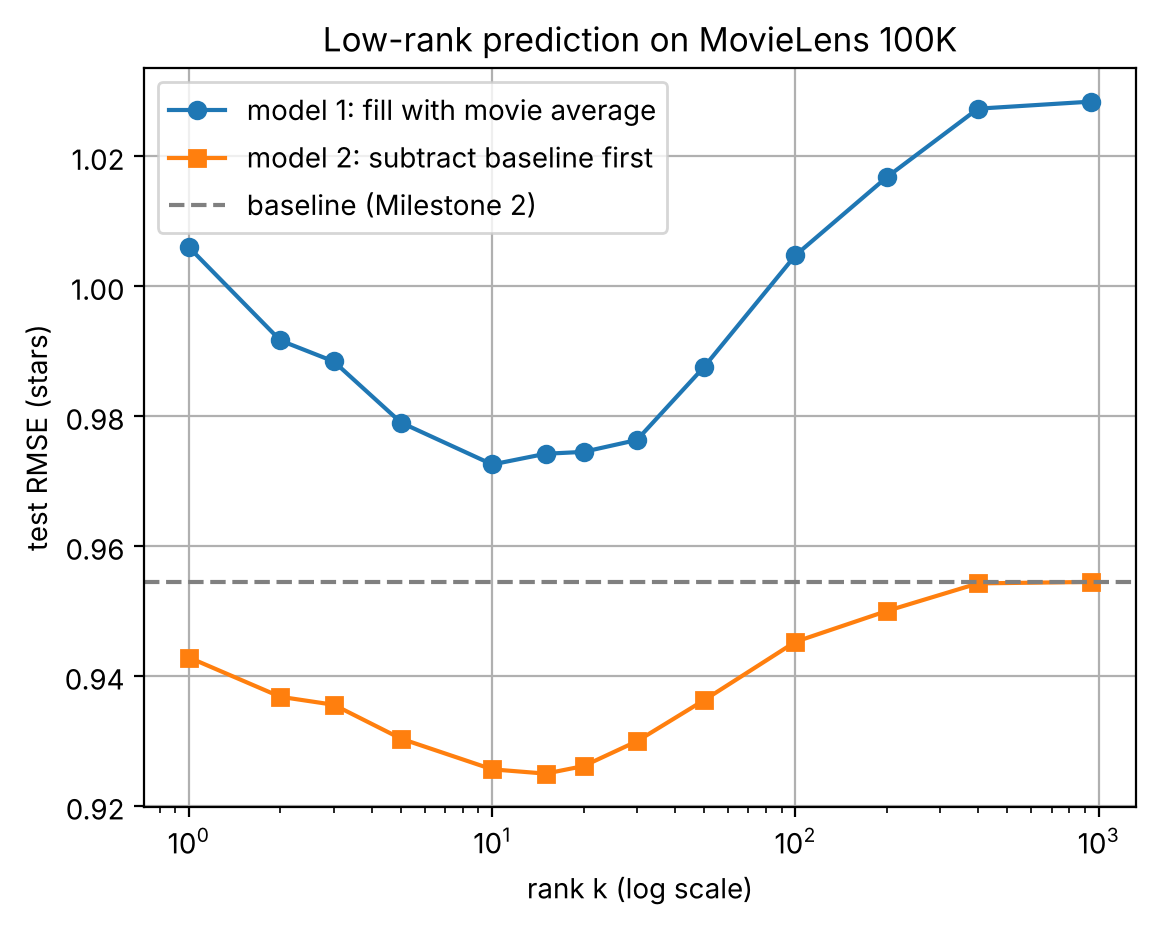

In [9]:
plt.semilogx(ks, err1, "o-", label="model 1: fill with movie average")
plt.semilogx(ks, err2, "s-", label="model 2: subtract baseline first")
plt.axhline(score(B), color="gray", ls="--", label="baseline (Milestone 2)")
plt.xlabel("rank k (log scale)")
plt.ylabel("test RMSE (stars)")
plt.title("Low-rank prediction on MovieLens 100K")
plt.grid(); plt.legend()
plt.savefig("rmse_vs_k.png", dpi=150)
plt.show()

This plots test RMSE against k for both models, with the baseline as a gray dashed line so it's easy to see whether a model is worth anything. `savefig` saves the plot as `rmse_vs_k.png` before `plt.show()`.

What I see in the plot:
- **Model 1 never beats the baseline.** Its best is 0.9726 at k = 10, which is worse than 0.9545. About 94% of the matrix is made-up movie averages, and the SVD learns those made-up numbers too.
- **Model 2 does beat it.** Its best is 0.9250 at k = 15 (0.9256 at k = 10), about 3.1% better than the baseline.
- **Both curves dip and then rise.** Small k is too simple and misses real patterns. Large k starts fitting noise in the training ratings and the made-up values in the gaps (overfitting). Only the test set shows this.
- **Check:** at k = 943 nothing is thrown away, so Model 1 gives 1.0284 (my Milestone 2 movie-average RMSE) and Model 2 gives 0.9545 (my baseline). That these match Milestone 2 shows the code is right.

## Model 3: refill the gaps and repeat

In [10]:
def iterative_svd_predict(R, k, n_iter=15):
    """Model 2, then repeatedly refill the gaps with the rank-k approximation."""
    known = ~ np.isnan(R)
    B = baseline_matrix(R)
    X = np.where(known, R - B, 0.0)
    for _ in range(n_iter):
        U, s, Vt = np.linalg.svd(X, full_matrices=False)
        L = rank_k(U, s, Vt, k)
        X = np.where(known, R - B, L)   # known ratings stay fixed
    return L + B

This starts like Model 2, but then repeats 15 times: compute the SVD, take the rank-k approximation `L`, and put `L`'s values into the gaps while the known ratings go back to their true values. Each round gives a better guess for the gaps. It's slower because it does a new SVD every round.

In [11]:
toy = np.array([
    [5, 4, 5, 1, np.nan, 2],
    [4, np.nan, 5, 2, 1, 1],
    [5, 5, np.nan, 1, 2, np.nan],
    [1, 2, 1, 5, 4, np.nan],
    [np.nan, 1, 2, 4, 5, 5],
    [2, 1, np.nan, 5, np.nan, 4],
])
users = ["Ana", "Ben", "Cal", "Dee", "Eve", "Fay"]
movies = ["Action 1", "Action 2", "Action 3", "Romance 1", "Romance 2", "Romance 3"]

B_toy = baseline_matrix(toy)
P_toy = np.clip(iterative_svd_predict(toy, k=1), 1, 5)
for r, c in np.argwhere(np.isnan(toy)):
    print(f"{users[r]} {movies[c]:10s} baseline: {B_toy[r, c]:.1f}  model 3: {P_toy[r, c]:.1f}")

Ana Romance 2  baseline: 3.4  model 3: 2.1
Ben Action 2   baseline: 2.1  model 3: 3.2
Cal Action 3   baseline: 3.5  model 3: 5.0
Cal Romance 3  baseline: 3.1  model 3: 1.4
Dee Romance 3  baseline: 2.5  model 3: 4.0
Eve Action 1   baseline: 3.8  model 3: 2.6
Fay Action 3   baseline: 3.2  model 3: 1.4
Fay Romance 2  baseline: 3.0  model 3: 4.5


Before using the real data, I tested Model 3 on the toy matrix from Milestone 1. `np.argwhere(np.isnan(toy))` lists the position of every gap. The baseline gets several of these backwards. For example, it predicts 3.4 for Ana on a romance movie, because it only knows averages. Model 3 with just one hidden factor (k = 1) finds the "action vs. romance" pattern. Its predictions agree with my Milestone 1 guesses in direction: Ana Romance 2 is low (2.1 vs. my 1), Cal Action 3 is high (5.0 vs. my 5), Dee Romance 3 is high (4.0 vs. my 5), and Fay Action 3 is low (1.4 vs. my 1).

In [12]:
for k in [2, 5, 10, 20]:
    print(f"k = {k:2d}  model 3: {score(iterative_svd_predict(R, k)):.4f}")

k =  2  model 3: 0.9291


k =  5  model 3: 0.9206


k = 10  model 3: 0.9347


k = 20  model 3: 0.9780


This runs Model 3 on the real data for a few values of k (each one takes a while because of the 15 SVDs). The best is **0.9206 at k = 5**, about 3.6% better than the baseline and the best result so far. Like in the handout, Model 3 prefers a smaller k than Model 2: at k = 10 it is already worse than Model 2 (0.9347 vs. 0.9256), and at k = 20 (0.9780) it is worse than the baseline. Each round makes the approximation fit the known ratings more closely, so extra factors start fitting noise sooner. (The handout's best was at k = 2; with my split it is k = 5, but the pattern is the same.)

### Summary

| Model | Best test RMSE (stars) |
|---|---|
| baseline (Milestone 2) | 0.9545 |
| model 1: fill with movie average, k = 10 | 0.9726 |
| model 2: subtract baseline first, k = 15 | 0.9250 |
| model 3: iterative, k = 5 | 0.9206 |

**Main finding:** linear algebra beats the best simple baseline, but only when it is combined with good modeling (subtracting the baseline first). The naive version (Model 1) is worse than the baseline at every k.

# Exercises

### Exercise 1: How much does the fill matter?

In [13]:
fills = {"movie average": F,
         "3 stars": np.where(known, R, 3.0),
         "0 stars": np.where(known, R, 0.0)}

fill_scores = {}
for name, Ffill in fills.items():
    Uf, sf, Vtf = np.linalg.svd(Ffill, full_matrices=False)
    fill_scores[name] = {k: score(rank_k(Uf, sf, Vtf, k)) for k in [5, 10, 20]}

fill_table = pd.DataFrame(fill_scores).T
fill_table.columns = [f"k = {k}" for k in fill_table.columns]
print(fill_table.round(4))

                k = 5  k = 10  k = 20
movie average  0.9790  0.9726  0.9745
3 stars        1.0697  1.0533  1.0554
0 stars        2.3357  2.2659  2.2650


From best to worst: **movie average (0.9726 at k = 10) > 3 stars (1.0533) > 0 stars (2.2659)**. Filling with movie averages is best because those guesses are already close to real ratings. Filling with 3 stars ignores that some movies are much better than others.

Filling with 0 is a disaster because about 94% of the matrix becomes "0 stars". The SVD sees a matrix that is almost all zeros and treats them as real ratings, so the low-rank approximation mostly learns "people rate almost everything 0". The predictions at the hidden ratings get pulled far below the 1–5 range, and even after clipping to 1 they are around 2 stars off, which is worse than just guessing 3 for everything (1.25).

### Exercise 2: Why does k = 943 give back the baseline?

In [14]:
print("Model 2, k = 943:", round(score(rank_k(U2, s2, Vt2, 943) + B), 4))
print("Baseline:        ", round(score(B), 4))

P_full = iterative_svd_predict(R, 943, n_iter=2)
print("Model 3, k = 943:", round(score(P_full), 4))
print("Model 3 equals B everywhere?", np.allclose(np.where(known, B, P_full), B))
print("Model 3 training error on known ratings:", round(np.abs(P_full[known] - R[known]).max(), 6))

Model 2, k = 943: 0.9545
Baseline:         0.9545


Model 3, k = 943: 0.9545
Model 3 equals B everywhere? True
Model 3 training error on known ratings: 0.0


**Model 2:** at k = 943 the rank-k approximation keeps every singular value, so it gives back X exactly. In X, every gap is 0, and all the test ratings are gaps. So the prediction at each test rating is 0 + B = B, and the RMSE is exactly the baseline's (0.9545). Nothing was thrown away, so nothing new was learned about the gaps.

**Model 3:** at full rank, L = X in every round, so `np.where(known, R - B, L)` puts back the same 0s in the gaps. X never changes, and the answer is again exactly B (the code confirms `P_full` equals `B` at every gap). It is useless because it fits the known training ratings perfectly (training error 0.0) but says nothing new about any missing rating. A perfect fit on the training data does not mean good predictions.

### Exercise 3: How many rounds?

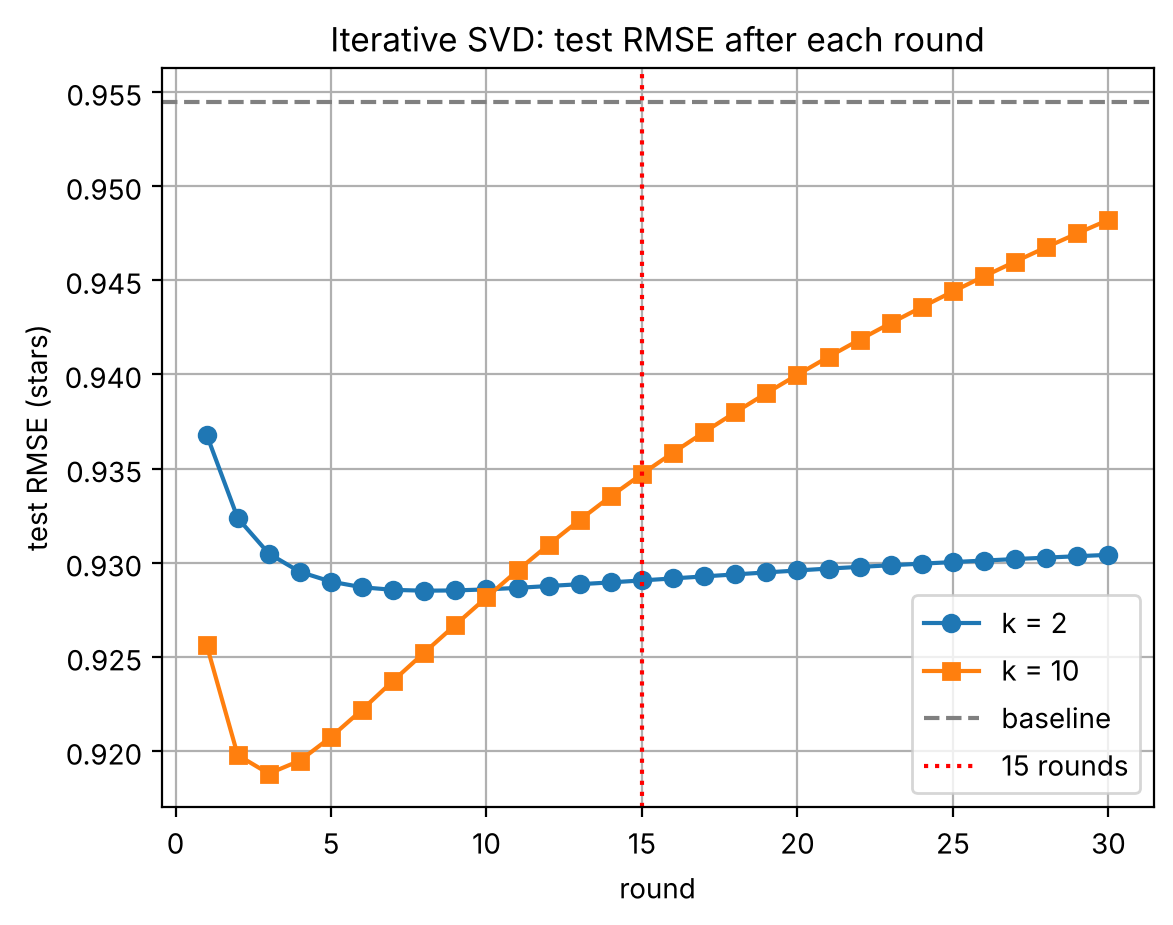

round  1  k=2: 0.9368  k=10: 0.9256
round  2  k=2: 0.9324  k=10: 0.9198
round  3  k=2: 0.9305  k=10: 0.9188
round  5  k=2: 0.9290  k=10: 0.9207
round 10  k=2: 0.9286  k=10: 0.9282
round 15  k=2: 0.9291  k=10: 0.9347
round 20  k=2: 0.9296  k=10: 0.9400
round 30  k=2: 0.9304  k=10: 0.9482


In [15]:
def iterative_svd_history(R, k, n_iter=15):
    """Same as iterative_svd_predict, but records the test RMSE after every round."""
    known = ~ np.isnan(R)
    B = baseline_matrix(R)
    X = np.where(known, R - B, 0.0)
    history = []
    for _ in range(n_iter):
        U, s, Vt = np.linalg.svd(X, full_matrices=False)
        L = rank_k(U, s, Vt, k)
        X = np.where(known, R - B, L)
        history.append(score(L + B))
    return history

rounds = np.arange(1, 31)
hist2 = iterative_svd_history(R, 2, n_iter=30)
hist10 = iterative_svd_history(R, 10, n_iter=30)

plt.plot(rounds, hist2, "o-", label="k = 2")
plt.plot(rounds, hist10, "s-", label="k = 10")
plt.axhline(score(B), color="gray", ls="--", label="baseline")
plt.axvline(15, color="red", ls=":", label="15 rounds")
plt.xlabel("round")
plt.ylabel("test RMSE (stars)")
plt.title("Iterative SVD: test RMSE after each round")
plt.grid(); plt.legend()
plt.savefig("rmse_vs_round.png", dpi=150)
plt.show()

for r in [1, 2, 3, 5, 10, 15, 20, 30]:
    print(f"round {r:2d}  k=2: {hist2[r-1]:.4f}  k=10: {hist10[r-1]:.4f}")

`iterative_svd_history` is the same as Model 3, but after every round it records `score(L + B)`. I ran 30 rounds so I could see what happens after round 15. (I kept this version in the notebook only, because it uses the test set through `score`.)

For **k = 2**, the error drops quickly in the first few rounds, bottoms out around 0.9285 near round 8–10, and then rises very slowly (0.9291 at round 15, 0.9304 at round 30). For k = 2, 15 rounds is fine; it's within about 0.0006 of the best.

For **k = 10**, the error is lowest after only 3 rounds (0.9188, which is better than any result in the main notebook), and then it climbs steadily: 0.9347 at round 15 and 0.9482 at round 30. So 15 rounds is too many for k = 10. The number of rounds should depend on k.

The k = 10 curve looks like the "dip, then rise" curve of test RMSE vs. k. It's **overfitting** again: each extra round fits the known training ratings more closely, so after a while the model is fitting noise. More rounds work like a larger k. Stopping early (after about 3 rounds) acts like choosing a smaller, simpler model.

### Exercise 4: Did we cheat a little?

In [16]:
# (a) split the training ratings again into fit and validation
fit, val = split_ratings(train, seed=1)
R_fit = to_matrix(fit)
known_fit = ~np.isnan(R_fit)
val_truth = val["rating"].to_numpy()
vu = val["user"].to_numpy() - 1
vi = val["item"].to_numpy() - 1
print("fit:", len(fit), " val:", len(val))

# (b) Model 2 on fit only, scored on the validation set
B_fit = baseline_matrix(R_fit)
X_fit = np.where(known_fit, R_fit - B_fit, 0.0)
Uf, sf, Vtf = np.linalg.svd(X_fit, full_matrices=False)

val_err = {}
for k in ks:
    P = rank_k(Uf, sf, Vtf, k) + B_fit
    val_err[k] = rmse(np.clip(P[vu, vi], 1, 5), val_truth)
    print(f"k = {k:3d}  validation RMSE: {val_err[k]:.4f}")

best_k = min(val_err, key=val_err.get)
print("best k on validation:", best_k)

fit: 81200  val: 8832


k =   1  validation RMSE: 0.9632
k =   2  validation RMSE: 0.9570
k =   3  validation RMSE: 0.9558
k =   5  validation RMSE: 0.9526
k =  10  validation RMSE: 0.9511
k =  15  validation RMSE: 0.9492
k =  20  validation RMSE: 0.9504
k =  30  validation RMSE: 0.9572
k =  50  validation RMSE: 0.9583
k = 100  validation RMSE: 0.9680
k = 200  validation RMSE: 0.9731
k = 400  validation RMSE: 0.9731
k = 943  validation RMSE: 0.9731
best k on validation: 15


In [17]:
# (c) rebuild Model 2 with best_k from ALL of train, score on test once
honest = score(rank_k(U2, s2, Vt2, best_k) + B)
best_test_k = ks[int(np.argmin(err2))]
print(f"honest Model 2 (k = {best_k}): test RMSE {honest:.4f}")
print(f"k picked by looking at the test set: {best_test_k}, test RMSE {min(err2):.4f}")

honest Model 2 (k = 15): test RMSE 0.9250
k picked by looking at the test set: 15, test RMSE 0.9250


I split the training ratings again (seed = 1) into a fit set (81200 ratings) and a validation set (8832 ratings). The test set was not used at all while choosing k. Using only the fit set, Model 2 had its lowest validation RMSE at **k = 15** (0.9492).

Then I rebuilt Model 2 with k = 15 from all of `train` and scored it on the test set once: **0.9250**.

The k I chose honestly is the same as the k I would pick by looking at the test set (k = 15), so in this case the honest test RMSE is the same, 0.9250. (Compared to the handout's 0.9332 it is lower, but that's because my split is different.) So the "cheating" did not change the result here. That was partly luck: the validation curve is very flat between k = 10 and k = 20, so it could easily have picked a slightly different k. The honest way is still the right way to report the result, because the 0.9250 now really is an estimate of how well the model works on ratings it has never seen.

### Exercise 5: Is it luck?

In [18]:
train1, test1 = split_ratings(ratings, seed=1)
R1 = to_matrix(train1)
known1 = ~np.isnan(R1)
truth1 = test1["rating"].to_numpy()
u1 = test1["user"].to_numpy() - 1
i1 = test1["item"].to_numpy() - 1

def score1(P):
    return rmse(np.clip(P[u1, i1], 1, 5), truth1)

B1 = baseline_matrix(R1)
X1 = np.where(known1, R1 - B1, 0.0)
U1s, s1s, Vt1s = np.linalg.svd(X1, full_matrices=False)

base0, m2_0 = score(B), score(rank_k(U2, s2, Vt2, best_k) + B)
base1, m2_1 = score1(B1), score1(rank_k(U1s, s1s, Vt1s, best_k) + B1)

seed_table = pd.DataFrame({
    "baseline": [base0, base1],
    f"model 2 (k = {best_k})": [m2_0, m2_1],
}, index=["seed 0", "seed 1"])
seed_table["improvement"] = seed_table.iloc[:, 0] - seed_table.iloc[:, 1]
seed_table["improvement %"] = 100 * seed_table["improvement"] / seed_table.iloc[:, 0]
print(seed_table.round(4))
print("\nchange in baseline RMSE between seeds:", round(abs(base1 - base0), 4))

        baseline  model 2 (k = 15)  improvement  improvement %
seed 0    0.9545            0.9250       0.0295         3.0917
seed 1    0.9577            0.9279       0.0298         3.1091

change in baseline RMSE between seeds: 0.0032


With the seed = 1 split, **Model 2 still wins**: 0.9279 vs. a baseline of 0.9577, an improvement of 0.0298 stars (3.1%). With seed = 0 it was 0.0295 stars (3.1%), so the improvement is almost identical.

The baseline's RMSE only changes by 0.0032 stars between the two seeds, while the improvement from Model 2 is about 0.03 stars, roughly 9 times bigger. So the 3% improvement is large compared with the random change from one split to another, and it is not just luck. It's still important to compare models on the same split, because a difference of 0.003 could come from the split alone.

### Exercise 6: What does 0.93 mean?

A test RMSE of 0.93 means that when my recommender guesses how many stars you would give a movie you haven't rated, it is typically off by a little less than one star. For example, if it predicts 4 stars, you would most likely give it somewhere between 3 and 5. That's good enough to separate movies you will probably like from ones you probably won't, but not good enough to tell a 4-star movie from a 5-star one.